# Stencil Computation for 2D Gray-Scott Using Julia

# 1. Setup

The setup is the same as in the GPU introduction, which explains it. The cells below activate the project environment, install and load the packages, and select the backend; set `DEV` in the last cell to match your hardware.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))


  Activating project at `c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions`


In [2]:
Pkg.add(["BenchmarkTools", "ProgressMeter", "Plots", "ColorTypes", "KernelAbstractions", "CUDA", "AMDGPU", "Metal"])

   Resolving package versions...
     Project No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
    Manifest No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Manifest.toml`


In [3]:
using BenchmarkTools, ProgressMeter, Plots, ColorTypes, KernelAbstractions


In [4]:
Pkg.status()

Status `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
⌃ [21141c5a] AMDGPU v2.10.0
  [6e4b80f9] BenchmarkTools v1.8.0
⌃ [052768ef] CUDA v6.5.0
  [3da002f7] ColorTypes v0.12.5
  [7073ff75] IJulia v1.34.4
  [63c18a36] KernelAbstractions v0.10.4
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [37e2e46d] LinearAlgebra v1.12.0
Info Packages marked with ⌃ have new versions available and may be upgradable.


## 1.1. Selecting a backend

In [5]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :NVIDIA

if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

CUDABackend(false, false, false)

# 2. Gray-Scott Reaction-Diffusion Model

The Gray-Scott Reaction-Diffusion model is a mathematical model used to describe how two interacting substances, typically denoted as $U$ and $V$, evolve over time in a spatial domain. This model captures the combined effects of chemical reactions and diffusion, leading to complex pattern formations such as spots, stripes, and waves, which resemble natural phenomena like animal skin patterns or chemical reactions in a petri dish.

## 2.1. Equations

The evolution of $ U $ and $ V $ over time is described by the following partial differential equations (PDEs):

$$
\frac{\partial U}{\partial t} = D_u \nabla^2 U - UV^2 + F(1 - U)
$$

$$
\frac{\partial V}{\partial t} = D_v \nabla^2 V + UV^2 - (F + k)V
$$

- **$D_u$**: Diffusion coefficient of $U$, controlling its spread rate.
- **$D_v$**: Diffusion coefficient of $V$, controlling its spread rate.
- **$F$**: Feed rate of  $U$, representing the replenishment of  $U$ in the system.
- **$ k $**: Kill rate of $V$, representing the removal of $V$ from the system.
- **$ \nabla^2 $**: Laplacian operator, representing the diffusion term.

## 2.2. 2D 5-Point Stencil

The 2D 5-point stencil is used to compute the diffusion terms ($ D_u \nabla^2 U $ and $ D_v \nabla^2 V $) in the Gray-Scott reaction-diffusion equations. It helps model how the substances $ U $ and $V $ spread through the 2D spatial domain by capturing the local flow of concentration between neighboring points.

<img src="../img/stencil_image1.png" alt="Input grid, 5-point stencil operator, and output grid" style="max-width:680px; width:100%; height:auto; display:block;" />

The left grid is the input field. The center shows the five cells the stencil touches at $(i, j)$: the point itself and its four orthogonal neighbors. The right grid is where the updated value is written. Every interior point of $U$ and $V$ is updated this way each time step.

<img src="../img/stencil_image2.webp" alt="5-point stencil $S_{i,j}$ centered on $v_{i,j}$ with four neighbors" style="max-width:300px; width:100%; height:auto; display:block;" />

On the mesh, $S_{i,j}$ is that same cross: the black center $v_{i,j}$ and the four yellow neighbors. Points on the domain edge are missing a neighbor, so the code below skips the boundary (ghost) cells and applies the stencil only for $2 \le x \le n-1$ and $2 \le y \le n-1$.

### 2.3. Mathematical Formulation

The Laplacian of a function $ u $ at point $(i, j)$ using the 2D 5-point stencil is approximated as:

$$
\nabla^2 u_{i, j} \approx \frac{1}{h^2} \left( u_{i-1, j} + u_{i+1, j} - 2 \cdot u_{i, j} \right) + \frac{1}{h^2} \left( u_{i, j-1} + u_{i, j+1} - 2 \cdot u_{i, j} \right)
$$

- **$ h $** is the grid spacing (`dx` in the code).
- Each term is the centered second difference along one axis; adding them gives $\nabla^2 u$ from the five stencil points above.


# 3. From CPU to KernelAbstractions

Section 3.1 gives a reference CPU implementation. Exercise 6 describes the port to KernelAbstractions, and §3.3 is that port. A second, **parameterized** version is in `../proposed-solution/exercise_6_gray_scott_tuned.ipynb`: each work item updates a **`P` × `Q`** block of grid cells (`P` rows, `Q` columns), passed as `Val(P)` and `Val(Q)` at compile time.


## 3.1. Reference CPU implementation
We use Float32 for the fields and PDE parameters on CPU and GPU. Single precision is much faster on GPUs; Apple GPUs do not support Float64 in kernels.


This version is the baseline for correctness and performance. Tutorial code uses `my_gs_cpu!`, `my_simulate_gs_cpu`, and (after Exercise 6) `my_gs_gpu_kernel!` / `my_simulate_gs_gpu`, with `my_laplacian` shared by CPU and GPU. You will port `my_gs_cpu!` and `my_simulate_gs_cpu` to KernelAbstractions in §3.2.

In [6]:
# Reference CPU implementation — start from this, then port it to KernelAbstractions below.

function my_laplacian(A, x, y, dx)
    @inbounds DAx = (A[x-1, y] - (2 * A[x, y]) + A[x+1, y]) / dx
    @inbounds DAy = (A[x, y-1] - (2 * A[x, y]) + A[x, y+1]) / dx
    return DAx + DAy
end

function my_gs_cpu!(U, V, D_u, D_v, F, k, dt, dx, nx, ny, noise)
    ΔU = zeros(eltype(U), nx, ny)
    ΔV = zeros(eltype(U), nx, ny)

    for x in 2:(nx-1), y in 2:(ny-1)
        @inbounds ΔU[x, y] = my_laplacian(U, x, y, dx)
        @inbounds ΔV[x, y] = my_laplacian(V, x, y, dx)
    end

    UVV = U .* V .* V
    N = noise == 0 ? zeros(eltype(U), nx, ny) : noise .* randn(eltype(U), nx, ny)
    U .+= (D_u .* ΔU .- UVV .+ F .* (1 .- U) .+ N) .* dt
    V .+= (D_v .* ΔV .+ UVV .- (F .+ k) .* V) .* dt
    return
end

function my_simulate_gs_cpu(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                         init_multi = 0.5,
                         noise = 0.0f0,
                         D_u = 0.16f0,
                         D_v = 0.08f0,
                         F = 0.035f0,
                         k = 0.06f0,
                         dt = 1.0f0,
                         dx = 1.0f0,
                         plot_every = 500)

    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model (CPU)", xlabel="X", ylabel="Y")

    anim = Plots.@animate for T in 1:div(nsteps, plot_every)
        for t in 1:plot_every
            my_gs_cpu!(U, V, D_u, D_v, F, k, dt, dx, n, n, noise)
        end
        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model (CPU)")
    end
    gif(anim, "gs_cpu_serial.gif"; fps=10)
end

my_simulate_gs_cpu (generic function with 3 methods)

### 3.2. Timing the update

`my_simulate_gs_cpu` spends much of its time building the animation. The next cell times only the update, `my_gs_cpu!`, for 20 steps on grids from \(64^2\) to \(512^2\).

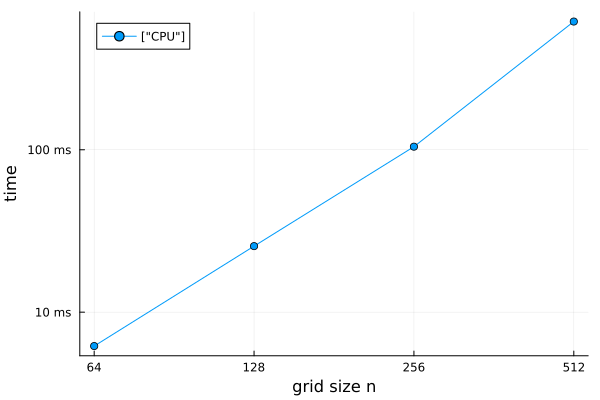

In [7]:
sizes = [64, 128, 256, 512]
gs_steps = 20
t_cpu = Float64[]
for n in sizes
    U, V = rand(Float32, n, n), rand(Float32, n, n)
    push!(t_cpu, @belapsed begin
        for _ in 1:gs_steps
            my_gs_cpu!($U, $V, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, $n, $n, 0.0f0)
        end
    end)
end

tlabel(v) = begin
    x, u = v < 1e-6 ? (v * 1e9, "ns") : v < 1e-3 ? (v * 1e6, "µs") : v < 1 ? (v * 1e3, "ms") : (v, "s")
    r = round(x; sigdigits = 2)
    string(isinteger(r) ? Int(r) : r, " ", u)
end

Plots.plot(sizes, t_cpu;
    label = ["CPU"],
    xlabel = "grid size n", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)),
    yformatter = tlabel, marker = :circle, legend = :topleft)

Progress: 100%|█████████████████████████████████████████| Time: 0:01:29
┌ Info: Saved animation to c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks\gs_cpu_serial.gif
└ @ Plots C:\Users\evely\.julia\packages\Plots\h49MV\src\animation.jl:156


 92.905914 seconds (378.49 M allocations: 49.691 GiB, 15.54% gc time, 1.36% compilation time: 7% of which was recompilation)


Plots.AnimatedGif("c:\\Users\\evely\\OneDrive\\Documents\\CSE_MIT\\julia-hpc-tutorial-sc26\\02-Parallel-Programming\\KernelAbstractions\\solved_notebooks\\gs_cpu_serial.gif")
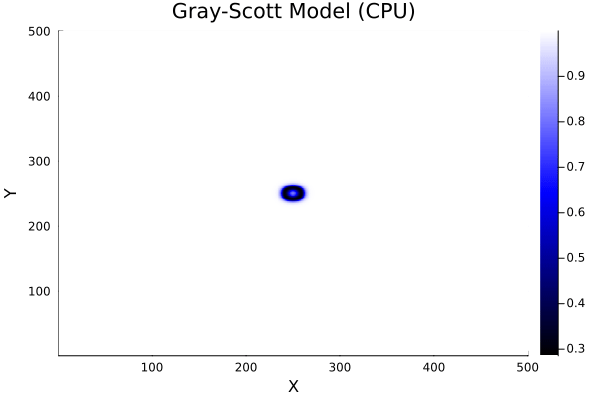

In [8]:
@time my_simulate_gs_cpu(500, 10000)

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 6: GPU implementation

§3.3 is the reference implementation from §3.1 ported to KernelAbstractions, on the `Backend` selected in §1.1. A second version in `../proposed-solution/exercise_6_gray_scott_tuned.ipynb` gives each work item a **`P` × `Q`** tile of the grid (`P` along `y`, `Q` along `x`; not the PDE parameters `F` or `k`). The function `my_laplacian`, the host-side initialization, seeding, progress bar and plotting loop, and the PDE update are the same as in the CPU version and already filled in. The following changes are required.

1. **Kernel.** Declare `my_gs_gpu_kernel!` with `@kernel function` instead of `function`, since only kernels are compiled for the device. The kernel is not called directly; `my_gs_gpu_kernel!(Backend, workgroupsize)` returns a launcher.

2. **Indexing.** Replace the serial loop by one work item per grid point, and skip the boundary cells as the CPU loop over `2:(n-1)` does:
   ```julia
   x, y = @index(Global, NTuple)
   if (1 < x < nx) && (1 < y < ny)
       ...
   end
   ```
   `ndrange=(n, n)` also launches work items on the boundary, and the `if` keeps them from reading outside the grid.

3. **Temporaries.** The CPU version keeps intermediate results in whole-domain arrays such as `ΔU = zeros(nx, ny)`. A work item needs only one value of each, declared with `@private` at the start of the kernel, before the index and the `if`:
   ```julia
   ΔU  = @private Float32 1
   ΔV  = @private Float32 1
   UVV = @private Float32 1
   Nr  = @private Float32 1
   DU  = @private Float32 1
   DV  = @private Float32 1
   ```
   These are accessed as `ΔU[1]`, `DU[1]`, and so on. Input and output fields live in device global memory (`KernelAbstractions.allocate`).

4. **Global writes.** Mark the input fields read-only with `@Const(U)` and `@Const(V)`, and write the updated values to separate outputs (same idea as the CPU `Unew` / `Vnew` buffers):
   ```julia
   @inbounds Uout[x, y] = newU
   @inbounds Vout[x, y] = newV
   ```
   In-place updates would race on stencil neighbors. The host driver keeps two device buffer pairs and **ping-pongs** read/write arrays each launch. The kernel must not contain a `return` statement.

5. **Driver.** Allocate four device arrays (`U1`, `V1`, `U2`, `V2`), copy the initial host data into both pairs, and build the launcher with `my_gs_gpu_kernel!(Backend, (cld(n, 16), cld(n, 16)))`. Each step launches with `(Uout, Vout, Uin, Vin, …)` and swaps which pair is read vs written. Before plotting, `copyto!` the current read buffer to host `U` and call `KernelAbstractions.synchronize(Backend)`.

</div>


## 3.3. Completed code

The kernel and driver below follow the tasks in Exercise 6.


In [9]:
# (1) @kernel — compiled for Backend
@kernel function my_gs_gpu_kernel!(Uout, Vout, @Const(U), @Const(V), D_u, D_v, F, k, dt, dx, nx, ny, noise)
    x, y = @index(Global, NTuple)

    if (1 < x < nx) && (1 < y < ny)
        u = @inbounds U[x, y]
        v = @inbounds V[x, y]

        ΔU = my_laplacian(U, x, y, dx)
        ΔV = my_laplacian(V, x, y, dx)
        UVV = u * v * v
        Nr = noise == 0 ? zero(u) : noise * randn(Float32)
        DU = D_u * ΔU - UVV + F * (1 - u) + Nr
        DV = D_v * ΔV + UVV - (F + k) * v
        newU = u + DU * dt
        newV = v + DV * dt

        @inbounds Uout[x, y] = newU
        @inbounds Vout[x, y] = newV
    end
end


function my_simulate_gs_gpu(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                        init_multi = 0.5,
                        noise = 0.0f0,
                        D_u = 0.16f0,
                        D_v = 0.08f0,
                        F = 0.035f0,
                        k = 0.06f0,
                        dt = 1.0f0,
                        dx = 1.0f0,
                        plot_every = 500)

    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, U)
    KernelAbstractions.copyto!(Backend, V1, V)
    KernelAbstractions.copyto!(Backend, U2, U)
    KernelAbstractions.copyto!(Backend, V2, V)

    kernel = my_gs_gpu_kernel!(Backend, (cld(n, 16), cld(n, 16)))
    readU, readV, writeU, writeV = U1, V1, U2, V2

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model", xlabel="X", ylabel="Y")

    anim = Plots.@animate for t in 1:div(nsteps, plot_every)
        for _ in 1:plot_every
            kernel(writeU, writeV, readU, readV, D_u, D_v, F, k, dt, dx, n, n, noise, ndrange=(n, n))
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end

        KernelAbstractions.copyto!(Backend, U, readU)
        KernelAbstractions.synchronize(Backend)

        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model")
    end
    gif(anim, "gs_ka.gif"; fps=10)
end


my_simulate_gs_gpu (generic function with 3 methods)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:36


 39.656079 seconds (404.43 M allocations: 13.232 GiB, 11.26% gc time, 19.33% compilation time: 52% of which was recompilation)


┌ Info: Saved animation to c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks\gs_ka.gif
└ @ Plots C:\Users\evely\.julia\packages\Plots\h49MV\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\evely\\OneDrive\\Documents\\CSE_MIT\\julia-hpc-tutorial-sc26\\02-Parallel-Programming\\KernelAbstractions\\solved_notebooks\\gs_ka.gif")
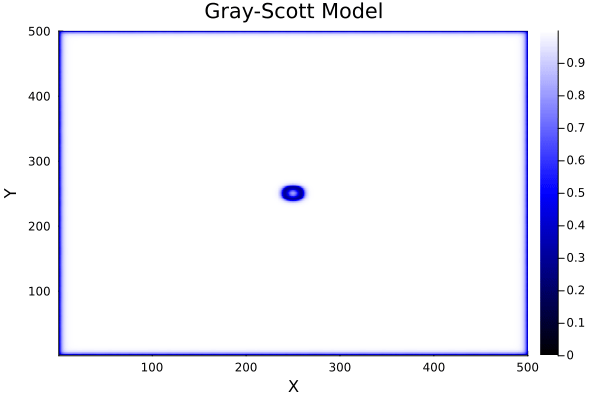

In [10]:
@time my_simulate_gs_gpu(500, 10000)

# 4. Experiments

## 4.1. The same grids on the GPU

The CPU update was timed in §3.1. Once `my_gs_gpu_kernel!` from Exercise 6 runs, the next cell times it for the same 20 steps and draws it beside that curve. The `@time` measurements on `my_simulate_gs_gpu` include the animation, so they answer a different question.

After that, vary the noise and the parameters of the PDE. The cells below are a few such runs.

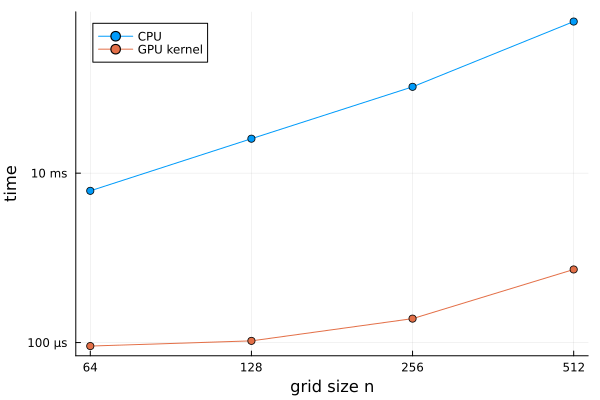

In [11]:
t_gpu = Float64[]
for n in sizes
    Uhost = rand(Float32, n, n)
    Vhost = rand(Float32, n, n)
    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, Uhost)
    KernelAbstractions.copyto!(Backend, V1, Vhost)
    KernelAbstractions.copyto!(Backend, U2, Uhost)
    KernelAbstractions.copyto!(Backend, V2, Vhost)
    k! = my_gs_gpu_kernel!(Backend, (cld(n, 16), cld(n, 16)))
    push!(t_gpu, @belapsed begin
        readU, readV, writeU, writeV = $U1, $V1, $U2, $V2
        for _ in 1:gs_steps
            $k!(writeU, writeV, readU, readV, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, $n, $n, 0.0f0; ndrange = ($n, $n))
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end
        KernelAbstractions.synchronize($Backend)
    end)
end

Plots.plot(sizes, [t_cpu t_gpu];
    label = ["CPU" "GPU kernel"],
    xlabel = "grid size n", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)),
    yformatter = tlabel, marker = :circle, legend = :topleft)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:33


 36.853519 seconds (420.48 M allocations: 12.956 GiB, 10.39% gc time)


┌ Info: Saved animation to c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks\gs_ka.gif
└ @ Plots C:\Users\evely\.julia\packages\Plots\h49MV\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\evely\\OneDrive\\Documents\\CSE_MIT\\julia-hpc-tutorial-sc26\\02-Parallel-Programming\\KernelAbstractions\\solved_notebooks\\gs_ka.gif")
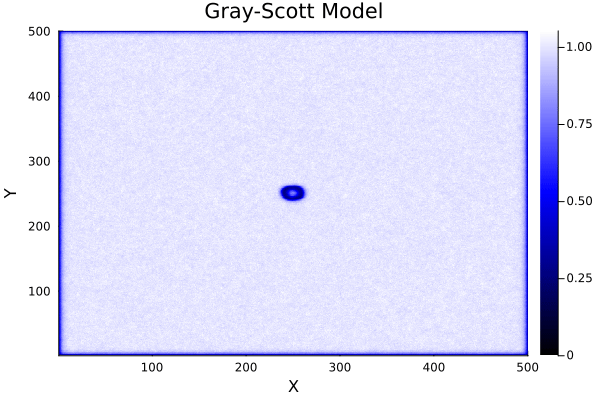

In [12]:
# Add some noise
@time my_simulate_gs_gpu(500, 10000; noise=0.01f0)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:33
┌ Info: Saved animation to c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks\gs_ka.gif
└ @ Plots C:\Users\evely\.julia\packages\Plots\h49MV\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\evely\\OneDrive\\Documents\\CSE_MIT\\julia-hpc-tutorial-sc26\\02-Parallel-Programming\\KernelAbstractions\\solved_notebooks\\gs_ka.gif")
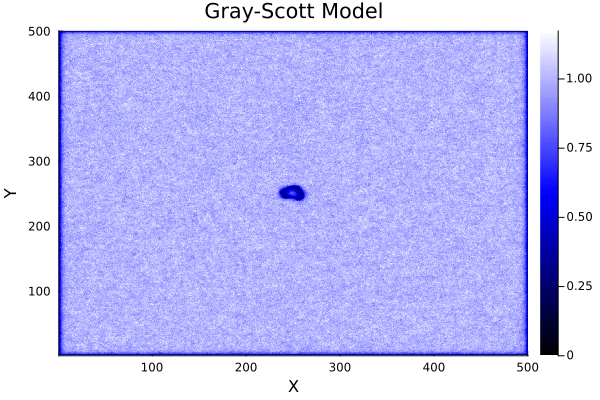

 36.525903 seconds (420.48 M allocations: 12.957 GiB, 10.55% gc time)


In [13]:
# Add a lot more noise
@time my_simulate_gs_gpu(500, 10000; noise=0.03f0)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:48


 51.829429 seconds (651.96 M allocations: 20.091 GiB, 11.99% gc time, 0.26% compilation time: <1% of which was recompilation)


┌ Info: Saved animation to c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\solved_notebooks\gs_ka.gif
└ @ Plots C:\Users\evely\.julia\packages\Plots\h49MV\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\evely\\OneDrive\\Documents\\CSE_MIT\\julia-hpc-tutorial-sc26\\02-Parallel-Programming\\KernelAbstractions\\solved_notebooks\\gs_ka.gif")
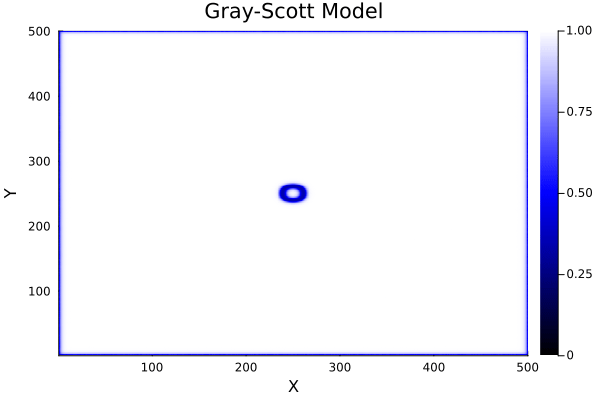

In [14]:
# Tweak some parameters
@time my_simulate_gs_gpu(500, 50000; k=.06054, F=.07528, noise=0.0001f0, init_multi=1.0, plot_every=2000)